# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

Code for reading files

In [2]:
def read_annotations_csv(filepath):
    annots_df = pd.read_csv(
        filepath,
        index_col=["CrossEra-ID"]
    )
    # Fix rows with multiple modes that were improperly handled
    bad_rows = annots_df.iloc[:, -1].notna()
    cols_from_mode = annots_df.loc[:, "Mode":]
    annots_df.update(cols_from_mode.loc[bad_rows].shift(-1, axis=1))
    annots_df.loc[bad_rows, "Mode"] = np.nan
    # Split lifetime into birth and death years, update Pierre Boulez's lifetime
    birth_death_cols = annots_df["CompLifetime"].str.split("-", expand=True)
    birth_death_cols.loc[annots_df["Composer"] == "Boulez; Pierre", 1] = 2016
    annots_df[["CompBirth", "CompDeath"]] = birth_death_cols.astype(int)
    # Add period column and specify which transitional period the addon composers are from
    annots_df["Period"] = annots_df["Class"].str.split("_", expand=True)[1]
    addon_bounds = [
        annots_df.loc[annots_df["Period"] == period, "CompBirth"].max()
        for period in ["classical", "romantic", "modern"]
    ]
    addon_periods = [f"addon_{trans}" for trans in ["bc", "cr", "rm"]]
    trans_dict = {bound: period for bound, period in zip(addon_bounds, addon_periods)}
    def specify_trans(birth):
        for bound in trans_dict:
            if birth < bound:
                return trans_dict[bound]
    addon_annots_df = annots_df.loc[annots_df["Period"] == "addon"]
    annots_df.loc[addon_annots_df.index, "Period"] = addon_annots_df["CompBirth"].apply(specify_trans)
    # Return relevant columns
    return annots_df[["Class", "Filename", "Instrumentation", "Period", "Key", "Mode", "Composer", "CompBirth", "CompDeath", "Country"]]

def _read_crossera_csv(filepath, names):
    df = pd.read_csv(filepath, header=None, names=["Class/Filename", "Time (seconds)"] + names, low_memory=False)
    df["CrossEra-ID"] = df["Class/Filename"].str.extract(r"\w+/(CrossEra-\d{4})")
    return df.drop(columns="Class/Filename").ffill().set_index(["CrossEra-ID", "Time (seconds)"])

def read_chroma_csv(filepath):
    return _read_crossera_csv(filepath, ["A", "A#", "B", "C", "C#", "D", "D#", "E", "F", "F#", "G", "G#"])

def read_chords_csv(filepath):
    return _read_crossera_csv(filepath, ["Chord Label"])["Chord Label"]

In [3]:
annots_df = read_annotations_csv("cross-era_annotations.csv")
chroma_df = pd.concat([
    read_chroma_csv(f"cross-era_chroma-nnls/chroma-nnls_{class_}.csv")
    for class_ in annots_df["Class"].unique()
])
chords_ser = pd.concat([
    read_chords_csv(f"cross-era_chords-chordino/chords-chordino_{class_}.csv")
    for class_ in annots_df["Class"].unique()
])

# Kolmogorov complexity

Implement LZ77 compression/decompression

In [4]:
# Adapted from https://timguite.github.io/jekyll/update/2020/03/15/lz77-in-python.html
from lz77.compress import compress, to_bytes

def lz77_ratio(x):
    return len(to_bytes(compress(x))) / len(x)

In [5]:
# Calculate compression ratio while discarding time information
annots_df["LZ77Ratio"] = annots_df.index.map(lambda x: lz77_ratio(chords_ser.loc[x].to_csv(header=False, index=False)))

In [6]:
period_order = ["baroque", "addon_bc", "classical", "addon_cr", "romantic", "addon_rm", "modern"]

def inst_histplots(x, binwidth, func=None, save=False, **kwargs):
    orch_annots_df = annots_df.loc[annots_df["Instrumentation"] ==  "orchestra"]
    piano_annots_df = annots_df.loc[annots_df["Instrumentation"] ==  "piano"]
    fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
    for ax, df, title in zip(axs, [orch_annots_df, piano_annots_df, annots_df], ["Orchestra", "Piano", "All"]):
        sns.histplot(
            df,
            x=df[x].apply(func) if func else x,
            hue="Period",
            hue_order=period_order,
            stat="probability",
            binwidth=binwidth,
            element="poly",
            fill=False,
            legend=title == "All",
            ax=ax,
            **kwargs
        )
        # sns.kdeplot(
        #     df,
        #     x=x,
        #     hue="Period",
        #     hue_order=period_order,
        #     # common_norm=False,
        #     legend=title == "All",
        #     ax=ax
        # )
        ax.set_title(title)
    plt.tight_layout()
    if save:
        x += f"_binwidth={binwidth}"
        if func:
            x += f",func={func.__name__}"
        if kwargs:
            x += f",{",".join(f"{k}={v}" for k, v in kwargs.items())}"
        plt.savefig(f"{x}_histplots.pdf")

def inst_regplots(y, save=False):
    orch_annots_df = annots_df.loc[annots_df["Instrumentation"] ==  "orchestra"]
    piano_annots_df = annots_df.loc[annots_df["Instrumentation"] ==  "piano"]
    fig, axs = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
    for ax, df, title in zip(axs, [orch_annots_df, piano_annots_df, annots_df], ["Orchestra", "Piano", "All"]):
        for period in period_order:
            period_df = df.loc[df["Period"] == period]
            sns.regplot(
                period_df,
                x=period_df[["CompBirth", "CompDeath"]].mean(axis=1),
                y=y,
                x_estimator=np.mean,
                label=period,
                ax=ax
            )
        # sns.lineplot(
        #     df,
        #     x=df[["CompBirth", "CompDeath"]].mean(axis=1),
        #     y=y,
        #     hue="Period",
        #     hue_order=period_order,
        #     legend=title == "Piano",
        #     ax=ax
        # )
        if title == "Piano":
            ax.legend(bbox_to_anchor=(1, 0.5), loc="center left")
        ax.set_title(title)
    plt.tight_layout()
    if save:
        plt.savefig(f"{y}_regplots.pdf")

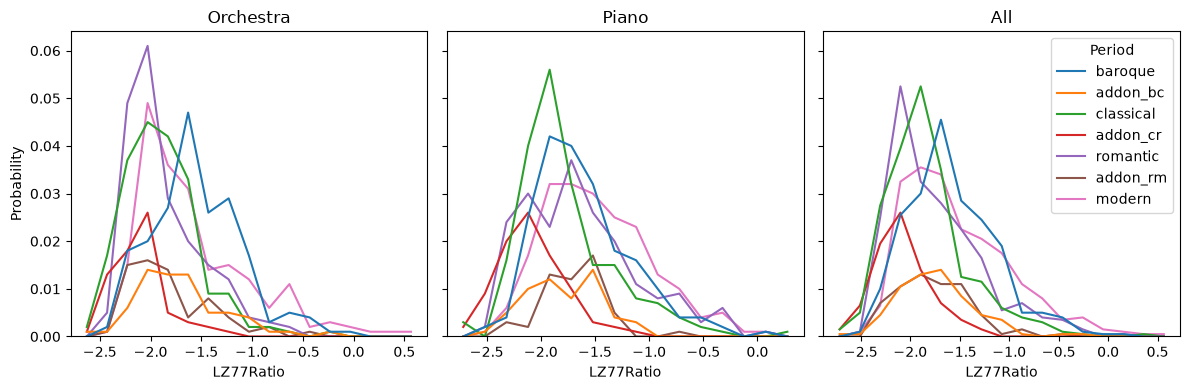

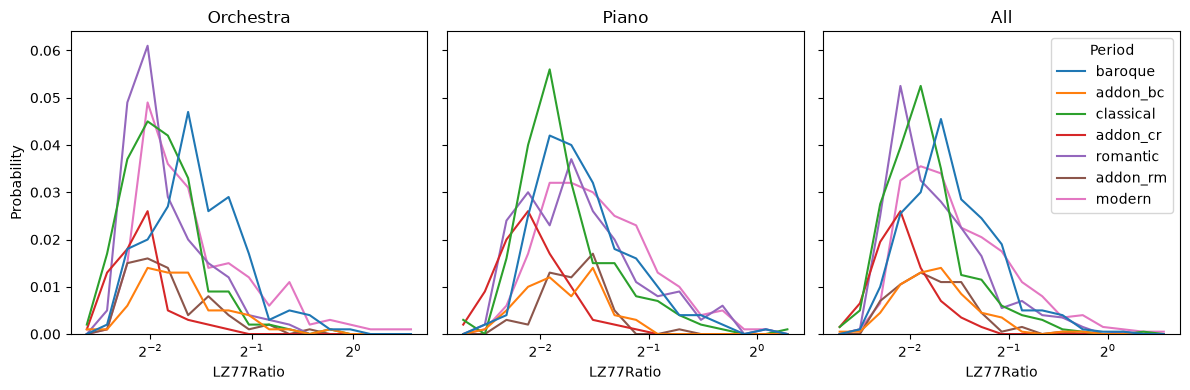

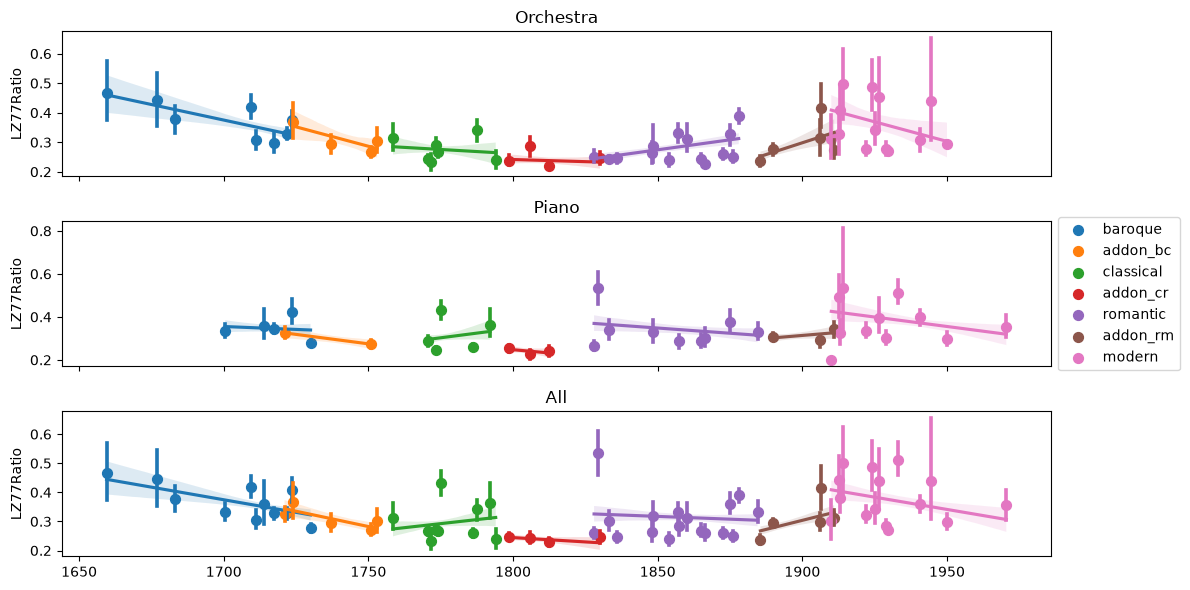

In [8]:
inst_histplots("LZ77Ratio", 0.2, np.log2) #, save=True)
inst_histplots("LZ77Ratio", 0.2, log_scale=2) #, save=True)
inst_regplots("LZ77Ratio") #, save=True)

# Conditional entropy

In [9]:
from collections import defaultdict

# Adapted from https://github.com/tjparmer/music-complexity
def conditional_entropy(array, lookback=1):
    array = tuple(array)

    biuniques = defaultdict(int)
    priors = defaultdict(int)
    total = len(array)

    for i in range(lookback, total):
        prior = array[i-lookback:i]
        priors[prior] += 1
        bielement = prior + (array[i],)
        biuniques[bielement] += 1

    # print(total, len(biuniques), len(priors))
    # print(f"Priors: {priors}")
    # print(f"Biuniques: {biuniques}")

    con_entropy = 0
    for key in biuniques:
        prior = key[:-1]
        px = priors[prior] / (total - lookback)
        pcon = biuniques[key] / priors[prior]
        con_entropy -= pcon * np.log2(pcon) * px
    return con_entropy

Calculate conditional entropy from chords

In [10]:
annots_df["ConditionalEntropy"] = annots_df.index.map(lambda x: conditional_entropy(chords_ser.loc[x]))

Plot distribution of conditional entropy categorised by periods

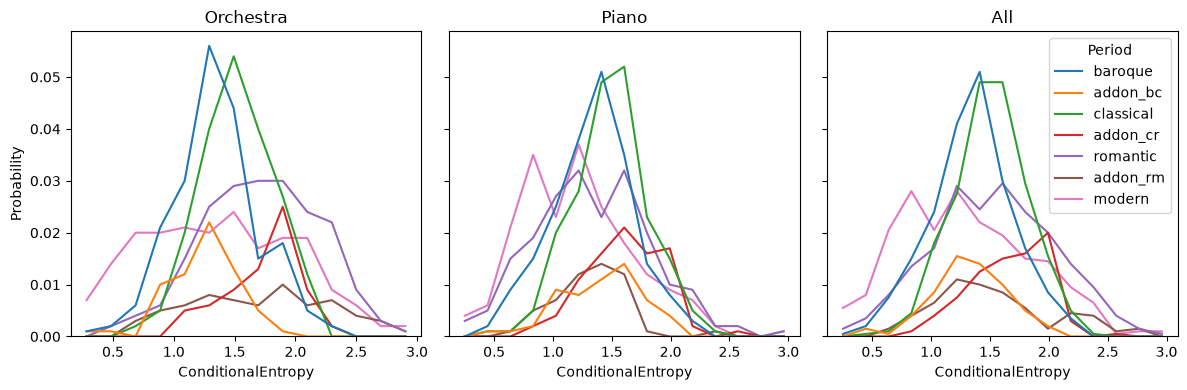

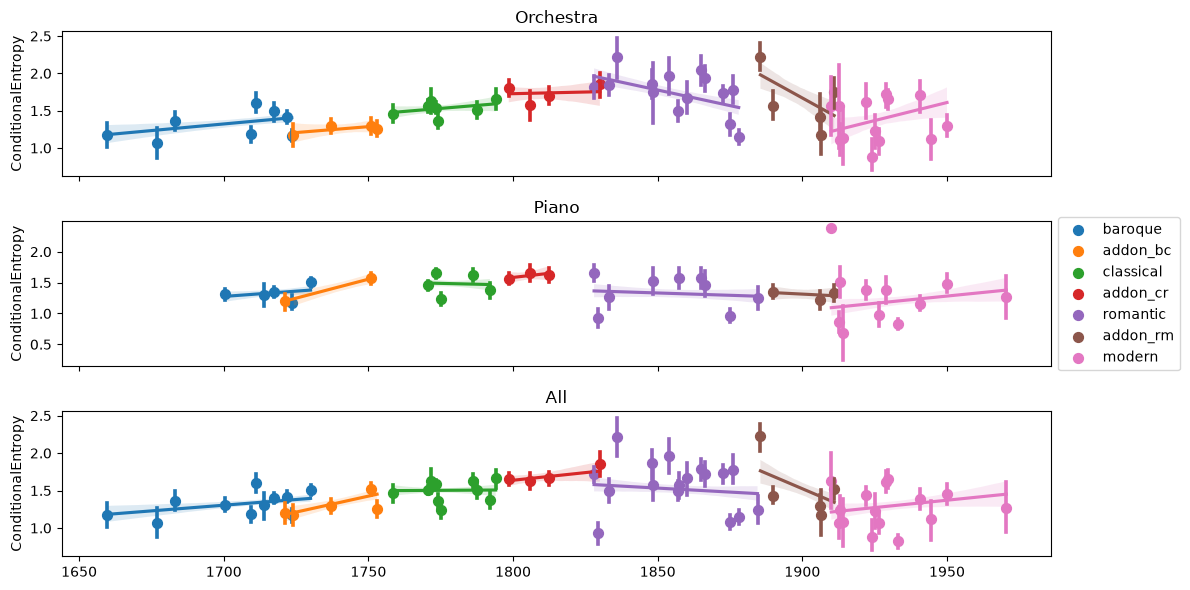

In [12]:
inst_histplots("ConditionalEntropy", 0.2) #, save=True)
inst_regplots("ConditionalEntropy") #, save=True)

# Complex networks

In [28]:
from itertools import pairwise

def create_chord_network(chords):
    G = nx.DiGraph()
    for a, b in pairwise(chords):
        if G.has_edge(a, b):
            G[a][b]["weight"] += 1
        else:
            G.add_edge(a, b, weight=1)
    # for (i, a), (j, b) in pairwise(chords_addon_ser_0.items()):
    #     if G.has_edge(a, a):
    #         G[a][a]["weight"] += j - i
    #     else:
    #         G.add_edge(a, a, weight=j - i)
    #     if G.has_edge(a, b):
    #         G[a][b]["weight"] += 0.1
    #     else:
    #         G.add_edge(a, b, weight=0.1)
    return G

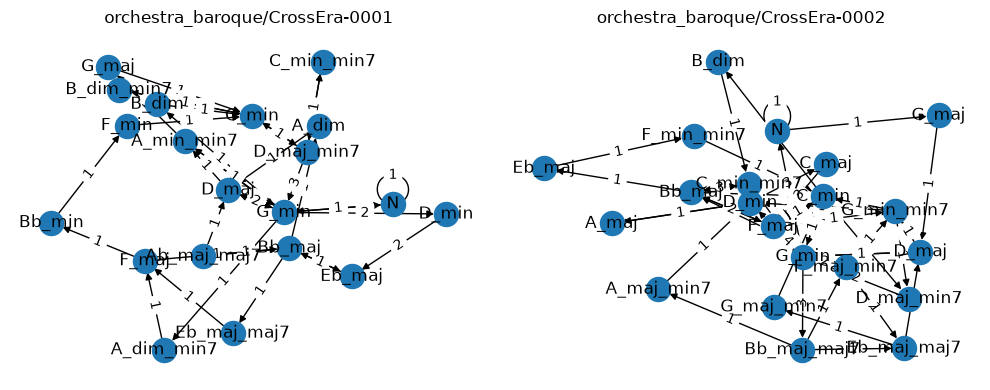

In [30]:
ncols = 2
fig, axs = plt.subplots(1, ncols, figsize=(5 * ncols, 4))

for i, (ax, name) in enumerate(zip(axs, annots_df.index)):
    chords_ser_i = chords_ser.loc[name]
    # print(len(chords_ser_i))
    G = create_chord_network(chords_ser_i)
    pos = nx.spring_layout(G, seed=42)
    edge_labels = nx.get_edge_attributes(G, "weight")
    # print(sorted(edge_labels.items(), key=lambda x: x[1], reverse=True))
    nx.draw(G, pos, ax=ax, with_labels=True)
    nx.draw_networkx_edge_labels(G, pos, edge_labels, ax=ax)
    ax.set_title(f"{"_".join(annots_df.loc[name, ["Instrumentation", "Period"]])}/{name}")

plt.tight_layout()
# plt.savefig("ComplexNetworks.pdf")

In [31]:
def network_metrics(chords):
    G = create_chord_network(chords)
    mean_degree = np.mean([d for _, d in G.degree])
    avg_dist = nx.average_shortest_path_length(G, weight="weight")
    mod_coms = nx.community.greedy_modularity_communities(G, weight="weight")
    modularity = nx.community.modularity(G, mod_coms)
    return mean_degree, avg_dist, modularity, len(mod_coms)

In [32]:
network_metrics_cols = pd.DataFrame.from_records(
    annots_df.index.map(lambda x: network_metrics(chords_ser.loc[x])),
    index=annots_df.index
)
annots_df[["NetworkMeanDegree", "NetworkAvgDist", "NetworkModularity", "NetworkNumModComs"]] = network_metrics_cols
annots_df["NetworkNumModComs"] = annots_df["NetworkNumModComs"].astype(int)

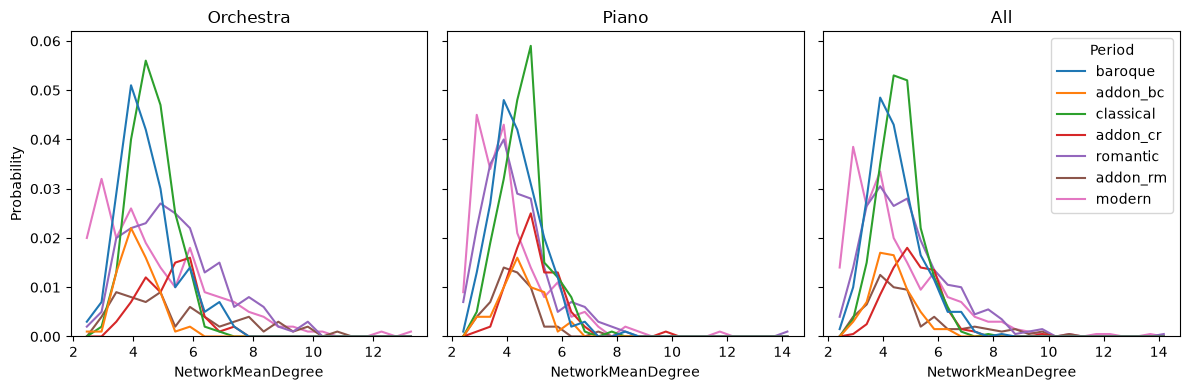

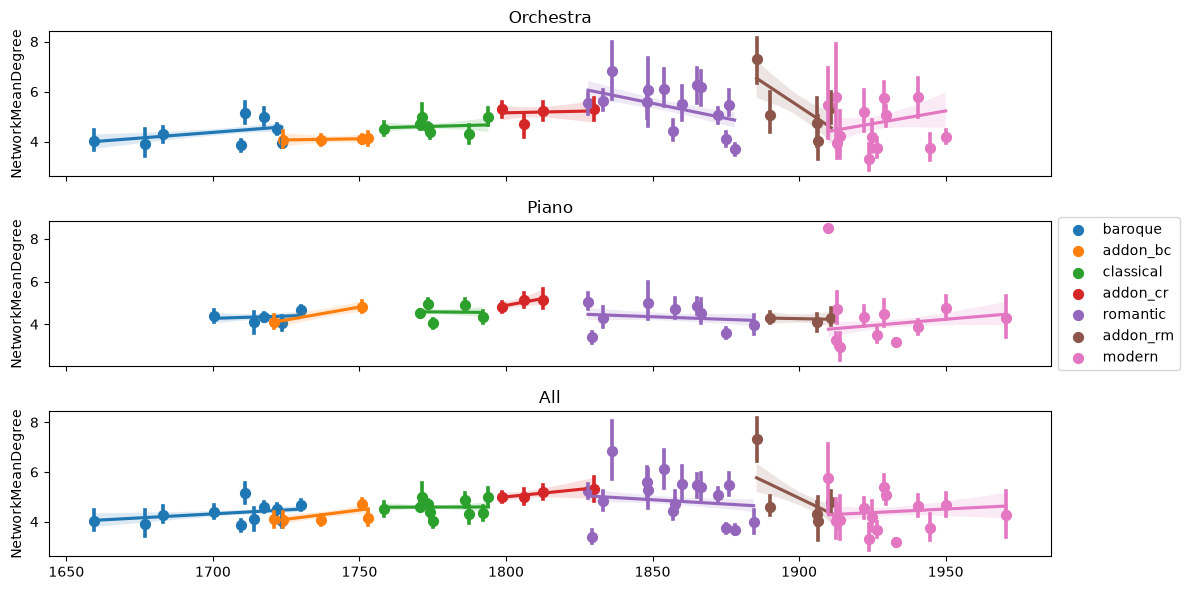

In [34]:
inst_histplots("NetworkMeanDegree", 0.5) #, save=True)
inst_regplots("NetworkMeanDegree") #, save=True)

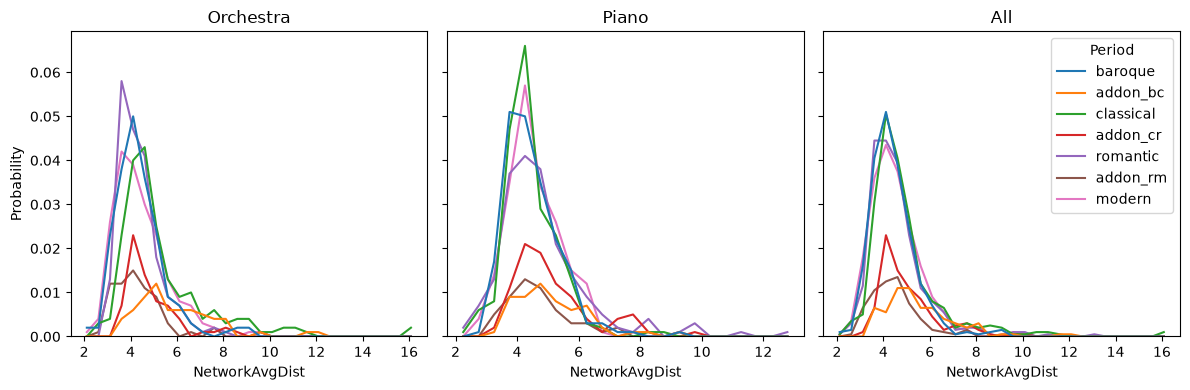

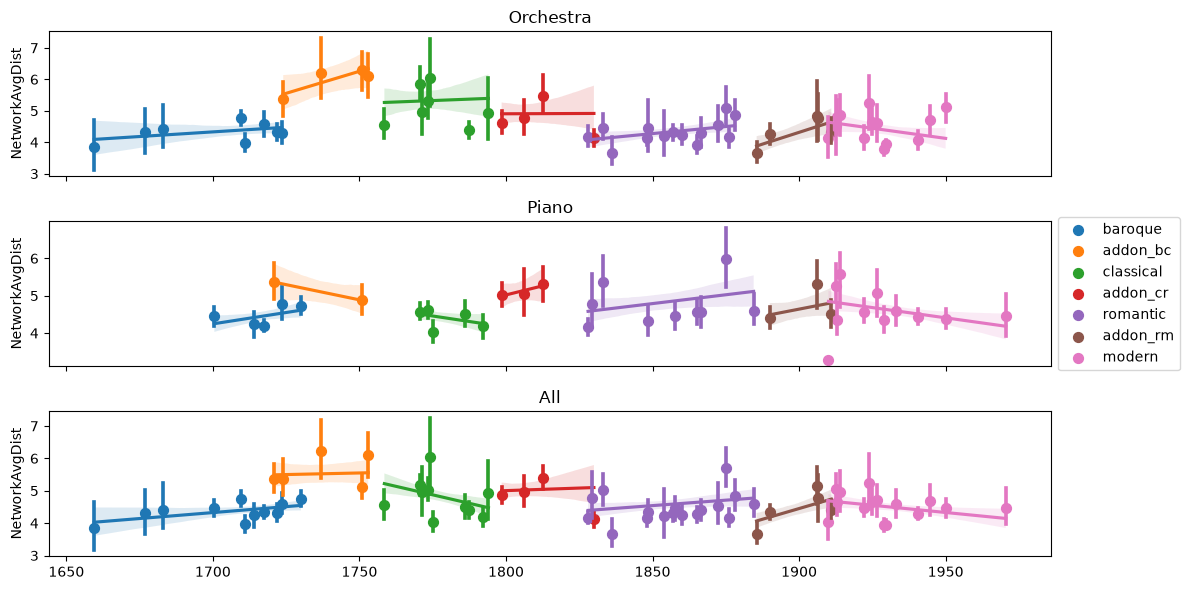

In [36]:
inst_histplots("NetworkAvgDist", 0.5) #, save=True)
inst_regplots("NetworkAvgDist") #, save=True)

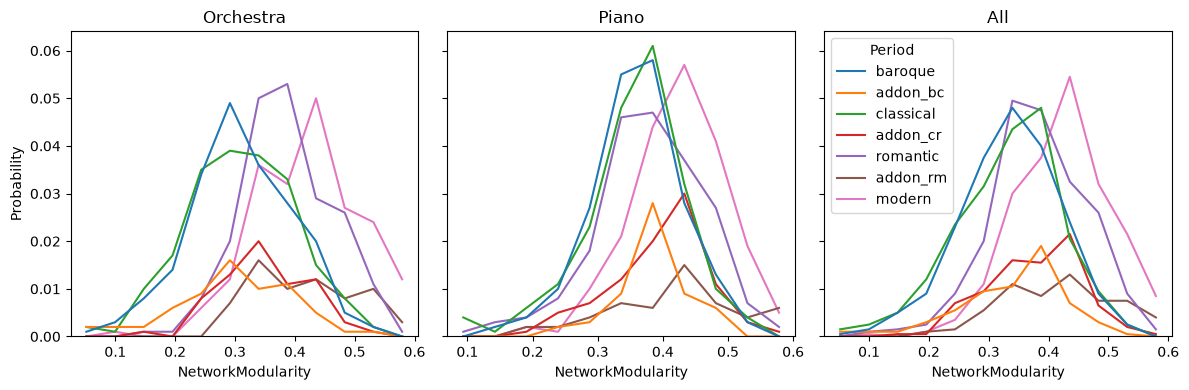

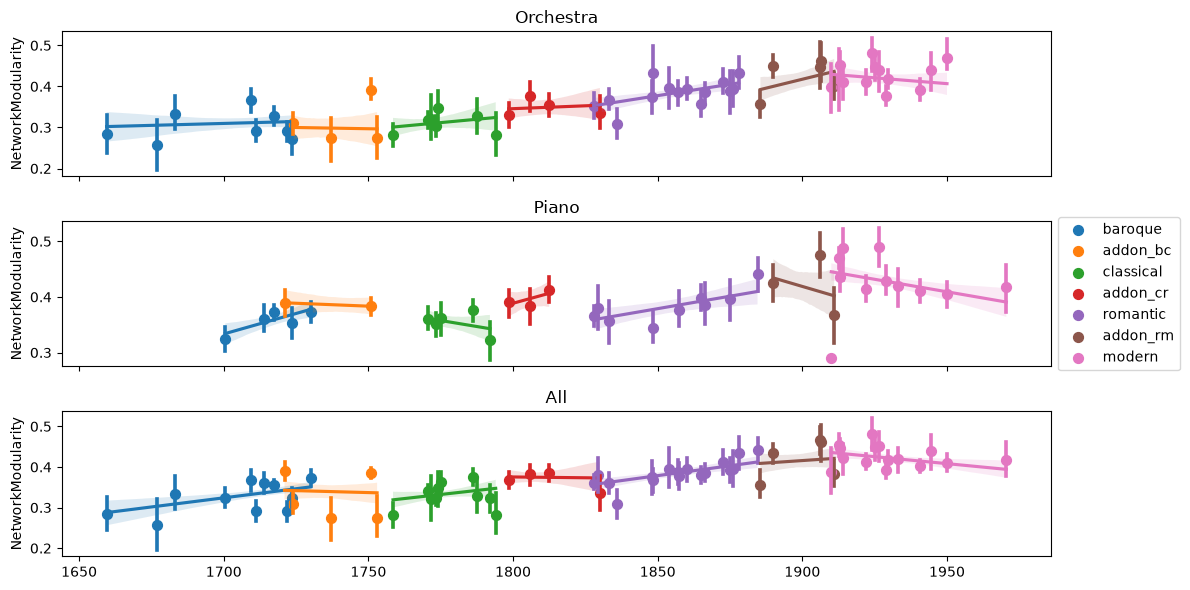

In [38]:
inst_histplots("NetworkModularity", 0.05) #, save=True)
inst_regplots("NetworkModularity") #, save=True)

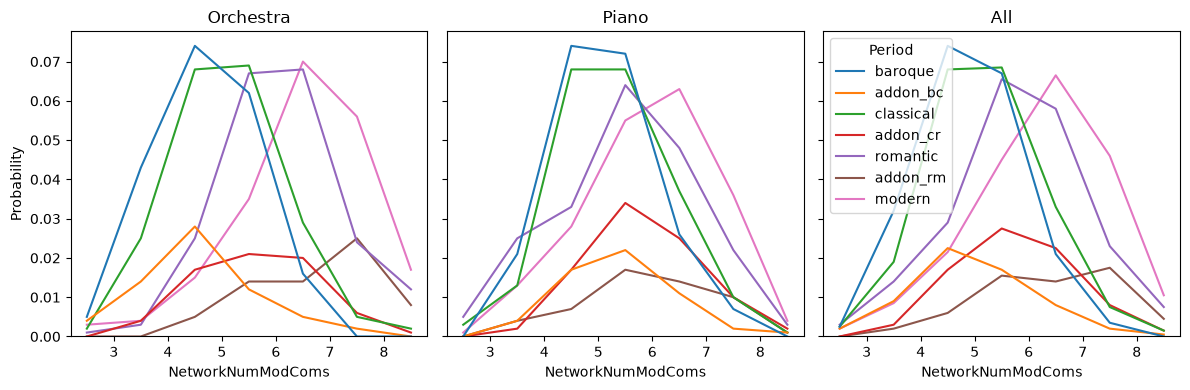

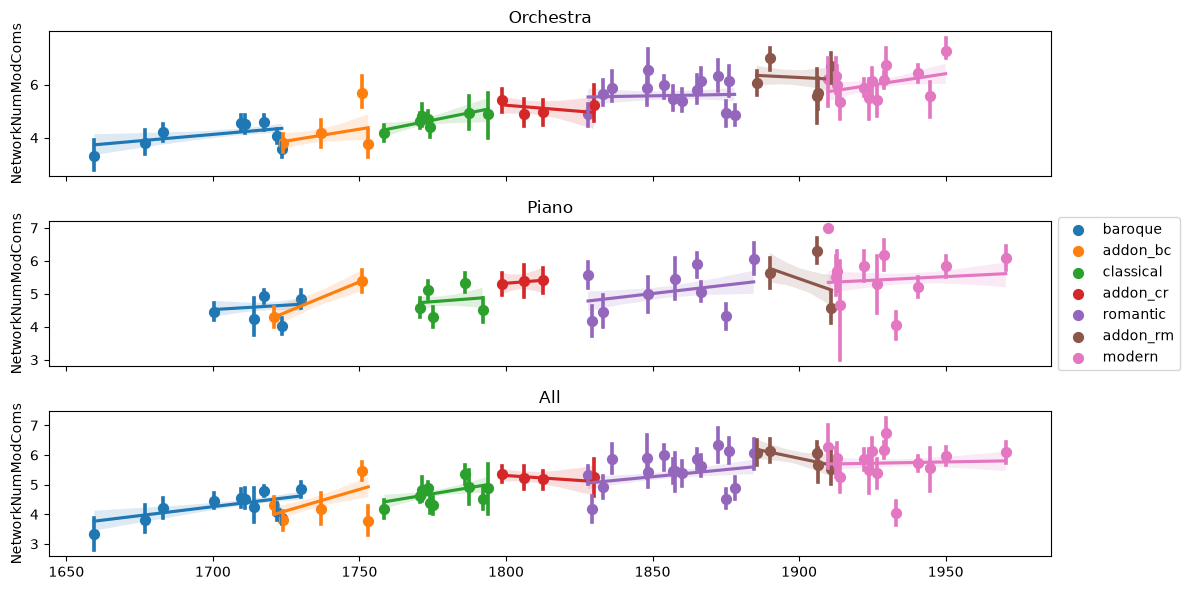

In [40]:
inst_histplots("NetworkNumModComs", 1) #, save=True)
inst_regplots("NetworkNumModComs") #, save=True)

# Novelty

Testing chromagram display

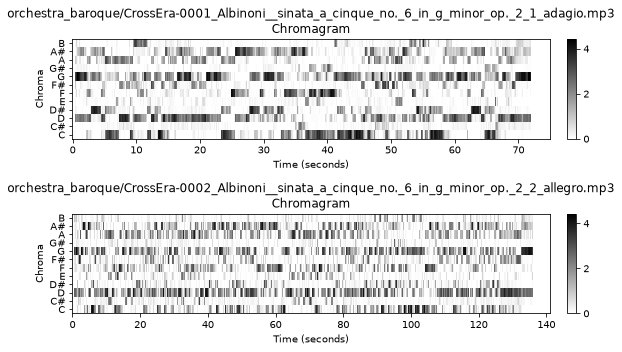

In [14]:
import libfmp.c3

chroma_label = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
nrows = 2
fig, ax = plt.subplots(nrows, 2, width_ratios=[1, 0.02], figsize=(8, 2.5 * nrows), dpi=72)

for i, name in enumerate(chroma_df.index.levels[0][:nrows]):
    C = chroma_df.loc[name][chroma_label]
    # Resolution is 10 Hz according to https://www.audiolabs-erlangen.de/resources/MIR/cross-era
    _, sub_ax, _ = libfmp.b.plot_chromagram(C.T, Fs=10, ax=[ax[i, 0], ax[i, 1]])
    sub_ax[0].set_title(f'{"/".join(annots_df.loc[name, ["Class", "Filename"]])} Chromagram', wrap=True)

plt.tight_layout()
# plt.savefig("Chromagram.pdf")

In [15]:
import libfmp.c4

# Adapted from LibFMP to display without annotations
def plot_feature_ssm(X, Fs_X, S, Fs_S, title='', label='Time (seconds)', figsize=(5, 6), clim_X=None, clim=None):
    """Plot SSM along with feature representation and annotations (standard setting is time in seconds)

    Notebook: C4/C4S2_SSM.ipynb

    Args:
        X: Feature representation
        Fs_X: Feature rate of ``X``
        S: Similarity matrix (SM)
        Fs_S: Feature rate of ``S``
        title: Figure title (Default value = '')
        label: Label for time axes (Default value = 'Time (seconds)')
        figsize: Figure size (Default value = (5, 6))
        clim_X: Color limits for matrix X (Default value = None)
        clim: Color limits for matrix ``S`` (Default value = None)

    Returns:
        fig: Handle for figure
        ax: Handle for axes
    """
    cmap = libfmp.b.compressed_gray_cmap(alpha=-10)
    fig, ax = plt.subplots(2, 2, width_ratios=[1, 0.05], height_ratios=[0.3, 1], figsize=figsize)
    libfmp.b.plot_chromagram(X, Fs=Fs_X, ax=[ax[0, 0], ax[0, 1]], clim=clim_X, xlabel='', ylabel='', title=title)
    ax[0, 0].tick_params("y", labelsize="x-small")
    libfmp.b.plot_matrix(S, Fs=Fs_S, ax=[ax[1, 0], ax[1, 1]], cmap=cmap, clim=clim, xlabel=label, ylabel=label)
    return fig, ax

def compute_smooth_ssm(X, Fs_X, filt_len=41, down_sampling=10):
    X, Fs_X = libfmp.c3.smooth_downsample_feature_sequence(X, Fs_X, filt_len=filt_len, down_sampling=down_sampling)
    X = libfmp.c3.normalize_feature_sequence(X, norm="2", threshold=0.001)
    S = libfmp.c4.compute_sm_dot(X, X)
    return S, X, Fs_X

def plot_smooth_ssm(X, Fs_X, filt_len=41, down_sampling=10):
    S, X, Fs_X = compute_smooth_ssm(X, Fs_X, filt_len=filt_len, down_sampling=down_sampling)
    fig, ax = plot_feature_ssm(X, Fs_X, S, Fs_X)
    return fig, ax, X, Fs_X, S


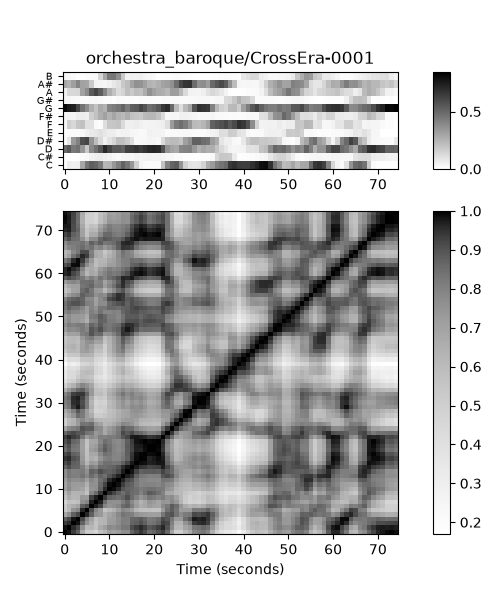
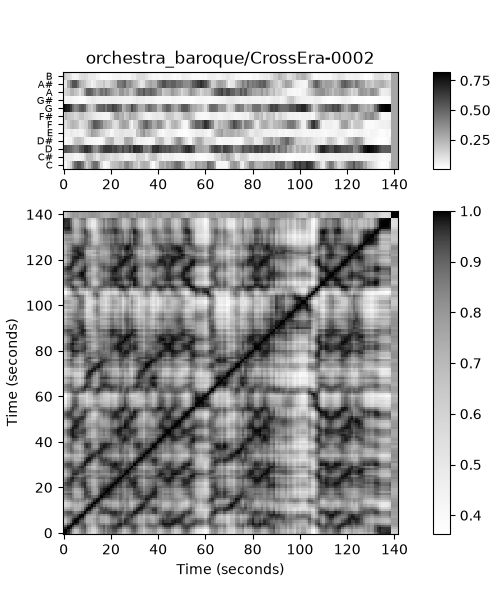

In [17]:
import libfmp.b

ncols = 2
float_box = libfmp.b.FloatingBox()

for i in range(ncols):
    name = chroma_df.index.levels[0][i]
    C = chroma_df.loc[name][chroma_label].to_numpy().T
    Fs_C = 10
    # S = libfmp.c4.compute_sm_dot(C, C)
    # fig, ax = plot_feature_ssm(C, Fs_C, S, Fs_C)
    fig, ax, C, Fs_C, S = plot_smooth_ssm(C, Fs_C)
    suptitle = f"{"_".join(annots_df.loc[name, ["Instrumentation", "Period"]])}/{name}"
    ax[0, 0].set_title(suptitle, wrap=True)
    float_box.add_fig(fig)
    # fig.savefig(f"SSM_{i}.pdf")
float_box.show()

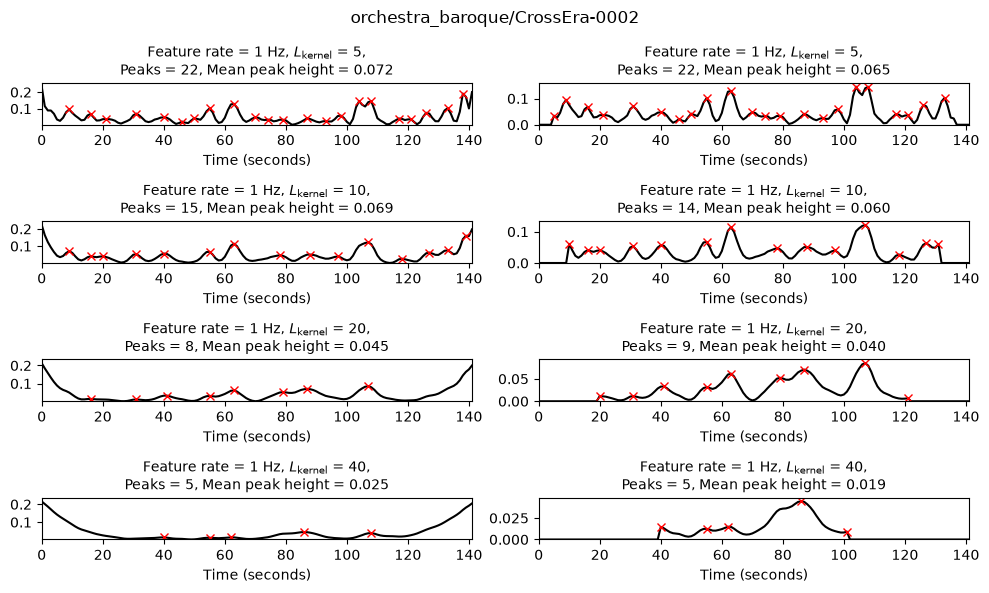

In [19]:
from scipy.signal import find_peaks

L_kernel_set = [5, 10, 20, 40]
figsize = (10, 1.5 * len(L_kernel_set))

fig, ax = plt.subplots(len(L_kernel_set), 2, figsize=figsize)
for s in range(2):
    for t, L_kernel in enumerate(L_kernel_set):
        nov = libfmp.c4.compute_novelty_ssm(S, L=L_kernel, exclude=s)
        peaks, _ = find_peaks(nov)
        fig_nov, ax_nov, line_nov = libfmp.b.plot_signal(nov, Fs=Fs_C, color='k', ax=ax[t, s], figsize=figsize)
        title = rf'Feature rate = {Fs_C:.0f} Hz, $L_\mathrm{{kernel}}$ = {L_kernel}'
        if len(peaks) > 0:
            title += f",\nPeaks = {len(peaks)}, Mean peak height = {np.mean(nov[peaks]):.3f}"
        ax_nov.set_title(title, fontsize="medium", wrap=True)
        ax_nov.plot(peaks / Fs_C, nov[peaks], "xr")
plt.suptitle(suptitle)
plt.tight_layout()
# plt.savefig("Novelty.pdf")

In [20]:
def novelty_peaks(C, Fs_C=10):
    S, C, Fs_C = compute_smooth_ssm(C, Fs_C)
    nov = libfmp.c4.compute_novelty_ssm(S, L=5, exclude=True)
    peaks, _ = find_peaks(nov)
    mean_peak_height = np.mean(nov[peaks])
    mean_peak_width = C.shape[1] / (Fs_C * len(peaks))
    return len(peaks), mean_peak_height, mean_peak_width

In [21]:
novelty_peaks_cols = pd.DataFrame.from_records(
    annots_df.index.map(lambda x: novelty_peaks(chroma_df.loc[x].to_numpy().T)),
    index=annots_df.index
)
annots_df[["NoveltyNumPeaks", "NoveltyMeanPeakHeight", "NoveltyMeanPeakWidth"]] = novelty_peaks_cols
annots_df["NoveltyNumPeaks"] = annots_df["NoveltyNumPeaks"].astype(int)

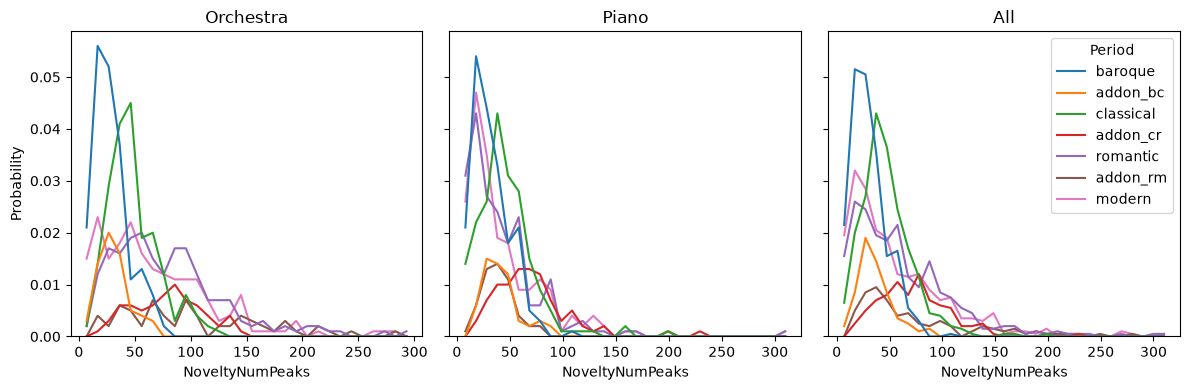

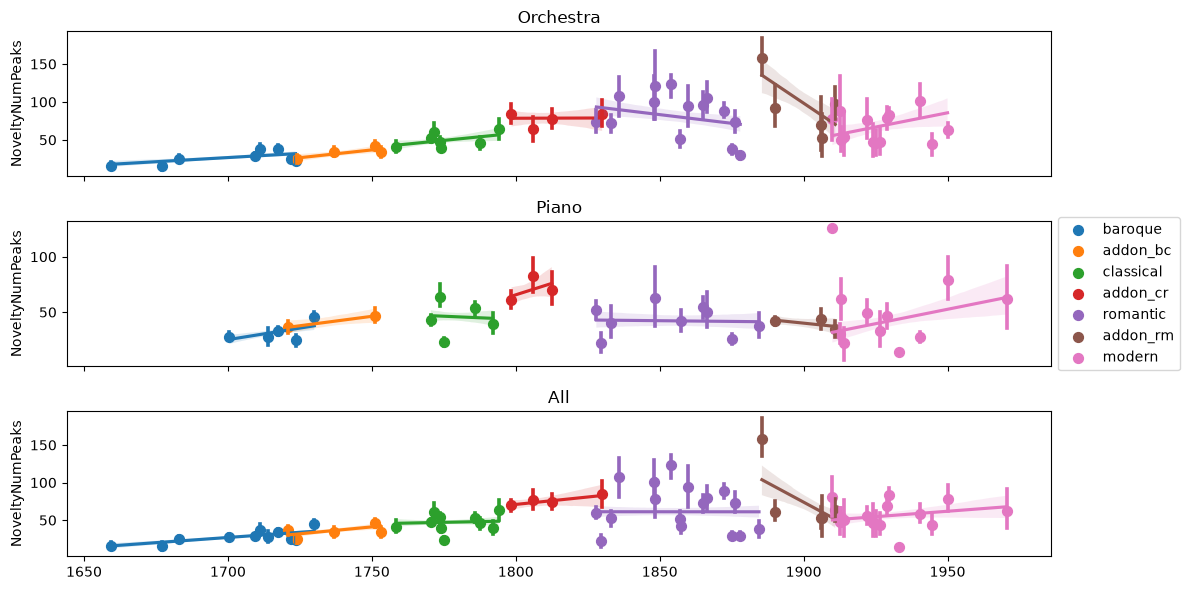

In [23]:
inst_histplots("NoveltyNumPeaks", 10) #, save=True)
inst_regplots("NoveltyNumPeaks") #, save=True)

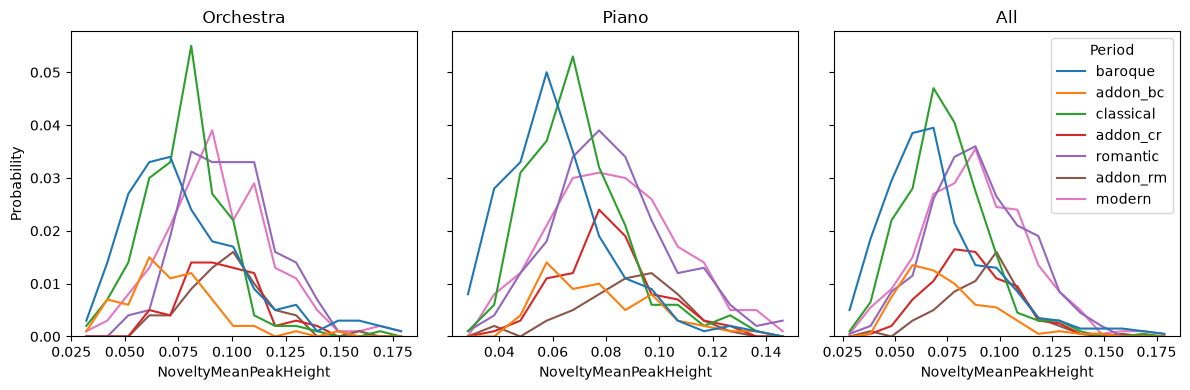

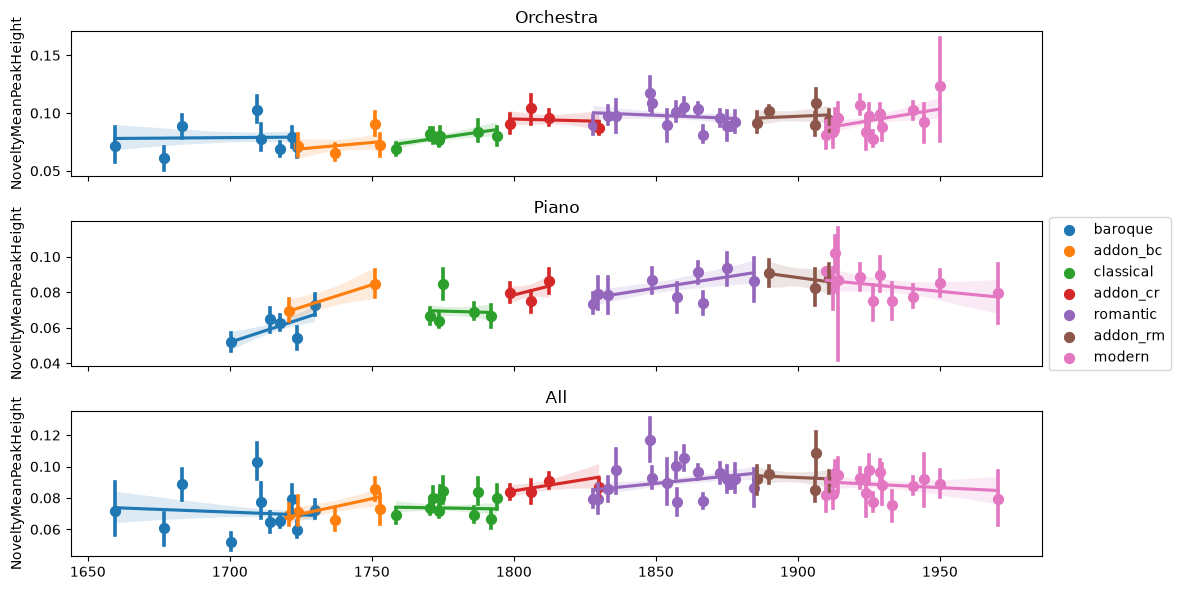

In [25]:
inst_histplots("NoveltyMeanPeakHeight", 0.01) #, save=True)
inst_regplots("NoveltyMeanPeakHeight") #, save=True)

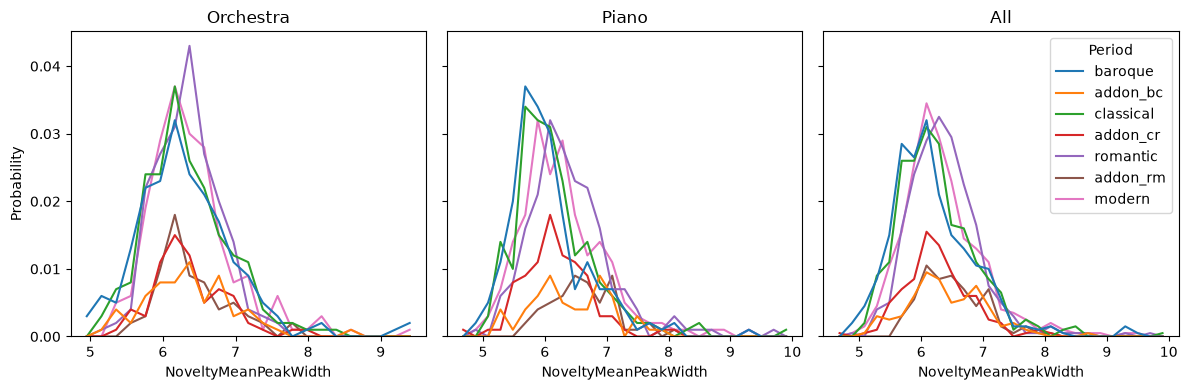

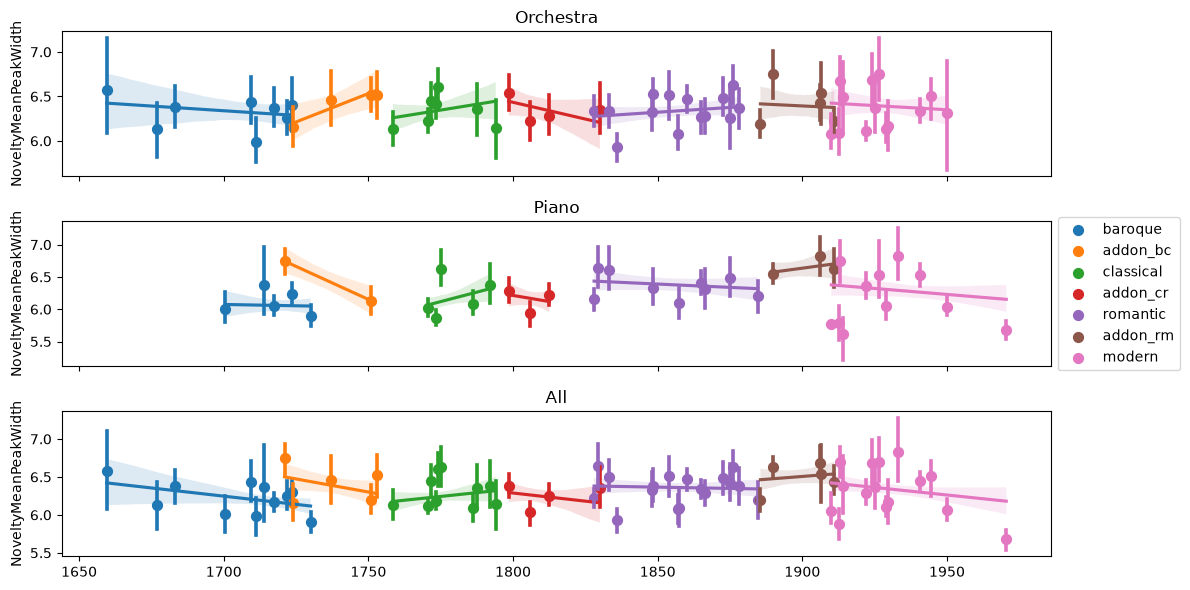

In [27]:
inst_histplots("NoveltyMeanPeakWidth", 0.2) #, save=True)
inst_regplots("NoveltyMeanPeakWidth") #, save=True)

# Linear Discriminant Analysis (LDA)

In [41]:
# bannots_df = annots_df.loc[annots_df["Period"].isin(period_order[::2])]
X = annots_df.iloc[:, -9:]
y = annots_df["Period"]
y.to_frame().join(X)

,Period,LZ77Ratio,ConditionalEntropy,NoveltyNumPeaks,NoveltyMeanPeakHeight,NoveltyMeanPeakWidth,NetworkMeanDegree,NetworkAvgDist,NetworkModularity,NetworkNumModComs
CrossEra-ID,,,,,,,,,,
CrossEra-0001,baroque,0.437126,0.997128,12,0.102973,6.250000,3.500000,6.094737,0.440000,4
CrossEra-0002,baroque,0.330961,1.507912,22,0.065139,6.454545,4.666667,4.283333,0.257600,5
CrossEra-0003,baroque,0.496667,1.238476,12,0.062429,5.833333,3.888889,3.647059,0.253968,5
CrossEra-0004,baroque,0.329365,1.452004,16,0.070084,7.250000,4.888889,4.303922,0.346648,4
CrossEra-0005,baroque,0.258498,1.857460,57,0.088841,5.543860,5.948718,3.473684,0.328094,6
...,...,...,...,...,...,...,...,...,...,...
CrossEra-1996,addon_cr,0.289003,1.704329,65,0.077728,6.338462,4.956522,4.054589,0.351690,5
CrossEra-1997,addon_cr,0.224247,1.747922,60,0.077750,5.766667,5.333333,4.250575,0.330234,4
CrossEra-1998,addon_cr,0.317045,1.595391,45,0.074674,6.444444,4.918919,3.638138,0.444600,6


In [42]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda = LDA()
X_lda = lda.fit_transform(X, y)

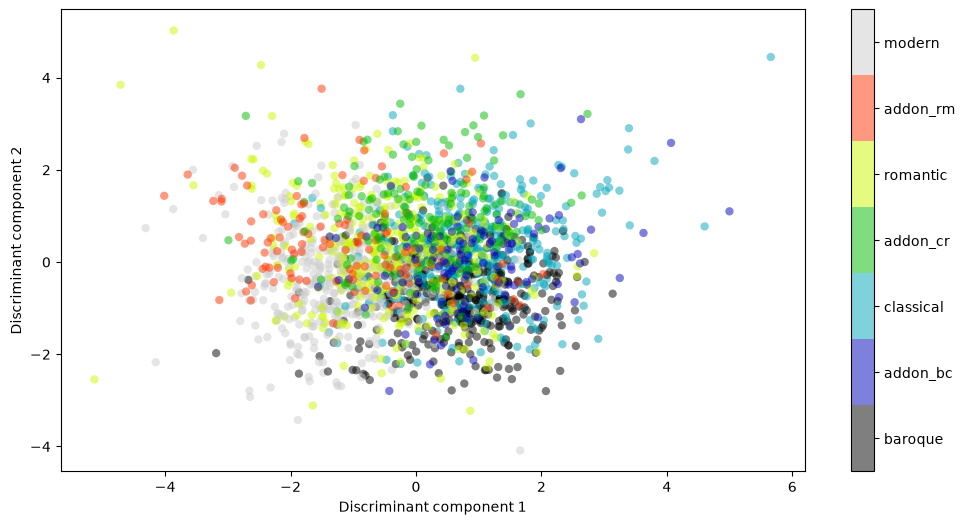

In [44]:
period_map = {period: i for i, period in enumerate(period_order)}
y_mapped = y.map(period_map)

plt.figure(figsize=(12, 6))
plt.scatter(
    X_lda[:, 0],
    X_lda[:, 1],
    c=y_mapped,
    edgecolor='none',
    alpha=0.5,
    cmap=plt.get_cmap('nipy_spectral', 7)
)
plt.xlabel('Discriminant component 1')
plt.ylabel('Discriminant component 2')
cbar = plt.colorbar()
start = (len(period_order) - 1) / (2 * len(period_order))
ticks = np.linspace(start, len(period_order) - 1 - start, num=len(period_order))
cbar.set_ticks(ticks, labels=period_order)
# plt.savefig("LDA.pdf")